<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/21_TimesSeriesForecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time series forecasting

## 1. Librerias y configuraciones previas


In [179]:
# Instalación de librerías
# ==============================================================================
!pip install sktime

In [180]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd


# Almacenar en caché los resultados de funciones en el disco
# ==============================================================================
import joblib


# Gestion de librerias
# ==============================================================================
from importlib import reload


# Preprocesado y modelado
# ==============================================================================

#Escalar Variables
from sklearn.preprocessing import MinMaxScaler


#configuracion de hiperparámetros
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

#creación de modelos
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

#Evaluar el modelo
from sklearn.metrics import (mean_absolute_error,
                             r2_score,
                             root_mean_squared_error)

from sktime.performance_metrics.forecasting import mean_absolute_scaled_error


# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

# Interuactuar con os y solicitudes desde HTTP
# ==============================================================================
import os
import sys
import requests

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

In [181]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '04_Metro_Interstate_Traffic_Volume.csv'
UTILS_FILE_NAME = 'funciones.py'
#UTILS_FILE_NAME2 = 'funciones2.py'

# Nombres de los directorios para utilidades, datasets y modelos
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'
MODELS_PATH = 'modelos/'
MODELS_REGRESION_PATH = os.path.join(MODELS_PATH, 'regresion')
MODELS_SCALER_PATH = os.path.join(MODELS_PATH, 'scaler')

# URL completa del dataset y utils en GitHub
github_dataset_url = os.path.join(GITHUB_BASE_URL, DATASETS_PATH, DATASET_FILE_NAME)
github_utils_url = os.path.join(GITHUB_BASE_URL, UTILS_PATH, UTILS_FILE_NAME)
github_utils_url2 = os.path.join(GITHUB_BASE_URL, UTILS_PATH, UTILS_FILE_NAME2)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)
local_utils_path2 = os.path.join(UTILS_PATH, UTILS_FILE_NAME2)

In [182]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio espefíficado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [183]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description):
    '''
    Descarga un archivo desde una URL y lo guarda localmente.

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
    Returns:
        None
    '''
    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [184]:
# Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)
#os.makedirs(MODELS_PATH, exist_ok=True)

# Crear subdirectorios específicos para modelos y escalados
#os.makedirs(MODELS_REGRESION_PATH, exist_ok=True)
#os.makedirs(MODELS_SCALER_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")

Descargando dataset desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/datasets/04_Metro_Interstate_Traffic_Volume.csv
dataset descargado exitosamente a: datasets/04_Metro_Interstate_Traffic_Volume.csv
Descargando funciones desde: https://raw.githubusercontent.com/mrbedoya/ml-2026/main/utils/funciones.py
funciones descargado exitosamente a: utils/funciones.py


## 2. Funciones

In [185]:
## Funciones externas
# ==============================================================================

## Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

## Importar Funciones externas
from funciones import multiple_plot, identificar_outliers, eval_model, \
                search_param, plot_param_perf


## 3. Carga del dataset

Metro Interstate Traffic Volume contiene 48.204 registros horarios, de 2012 a 2018, del volumen de tráfico en dirección oeste de la autopista I-94, entre Minneapolis y St. Paul (Minnesota). Cada registro incluye variables meteorológicas (temperatura, lluvia, nieve, nubosidad y descripción del clima) y si la fecha es festivo. La variable objetivo es traffic_volume, por lo que el dataset sirve para regresión y para pronóstico de series de tiempo. No tiene valores faltantes.


| Columna | Descripción | Ejemplo |
|---|---|---|
| `holiday` | Festivo nacional de EE. UU. o festivo regional (Minnesota State Fair). Si no es festivo, el valor es `None`. | `Labor Day` |
| `temp` | Temperatura promedio, en Kelvin. | `288.28` (≈ 15 °C) |
| `rain_1h` | Lluvia caída durante la hora, en mm. | `0.0` |
| `snow_1h` | Nieve caída durante la hora, en mm. | `0.0` |
| `clouds_all` | Porcentaje de nubosidad. | `40` |
| `weather_main` | Descripción corta del clima actual. | `Clouds` |
| `weather_description` | Descripción más detallada del clima actual. | `scattered clouds` |
| `date_time` | Fecha y hora de la medición, en hora local (CST). | `2012-10-02 09:00:00` |
| `traffic_volume` | Variable objetivo: volumen horario de tráfico en dirección oeste (vehículos por hora). | `5545` |

In [186]:
d = pd.read_csv(local_dataset_path)
d = d.sort_values(by='date_time')
#d = d.sample(10000, random_state=4321)

In [187]:
d.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.7+ MB


In [188]:
# Se convierte la variable date_time en el tipo de dato datetime
d['date_time'] = pd.to_datetime(d['date_time'], format='%Y-%m-%d %H:%M:%S')

In [189]:
# Se ordena el dataFrame por 'date_time'
d = d.sort_values(by='date_time')

In [190]:
# Se convierte la temperatura de °K a °C
d["temp"] = d["temp"] - 273.15

In [191]:
d.head(10)

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,15.1300,0.0000,0.0000,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,16.2100,0.0000,0.0000,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,16.4300,0.0000,0.0000,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,16.9800,0.0000,0.0000,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,17.9900,0.0000,0.0000,75,Clouds,broken clouds,2012-10-02 13:00:00,4918
5,NaN,18.5700,0.0000,0.0000,1,Clear,sky is clear,2012-10-02 14:00:00,5181
6,NaN,20.0200,0.0000,0.0000,1,Clear,sky is clear,2012-10-02 15:00:00,5584
7,NaN,20.7100,0.0000,0.0000,1,Clear,sky is clear,2012-10-02 16:00:00,6015
8,NaN,20.9900,0.0000,0.0000,20,Clouds,few clouds,2012-10-02 17:00:00,5791
9,NaN,19.9500,0.0000,0.0000,20,Clouds,few clouds,2012-10-02 18:00:00,4770


## 4. Visualización de datos

### Variables de entrada

In [192]:
#Lista de variables categóricas
catCols = d.select_dtypes(include = ["object", 'category']).columns.tolist()

d[catCols].head(2)

,holiday,weather_main,weather_description
0,NaN,Clouds,scattered clouds
1,NaN,Clouds,broken clouds


In [193]:
#Lista de variables numéricas

numCols=d.select_dtypes(include = ['float64','float32','int32','int64']).columns.tolist()
d[numCols].head(2)

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
0,15.1300,0.0000,0.0000,40,5545
1,16.2100,0.0000,0.0000,75,4516


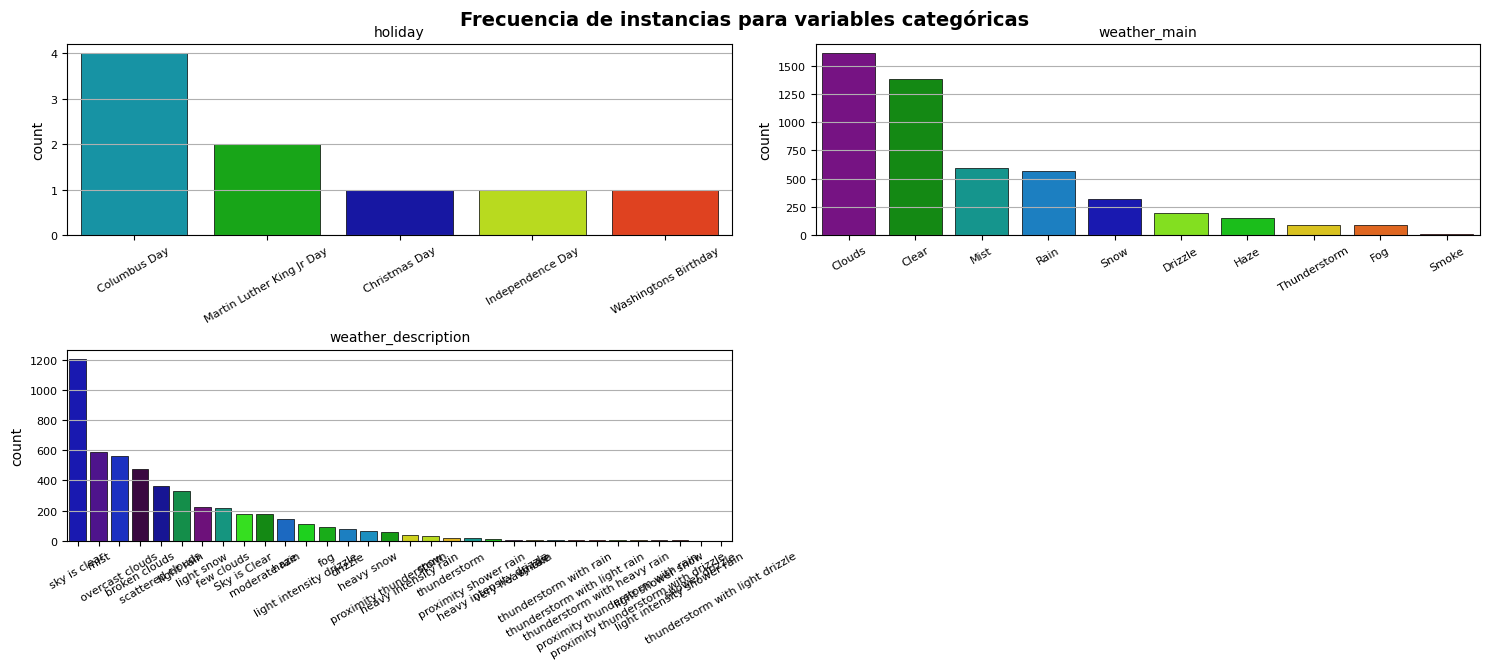

In [194]:
## Visualización de frecuencia de instancias para variables categóricas
multiple_plot(2, d.sample(5000) , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

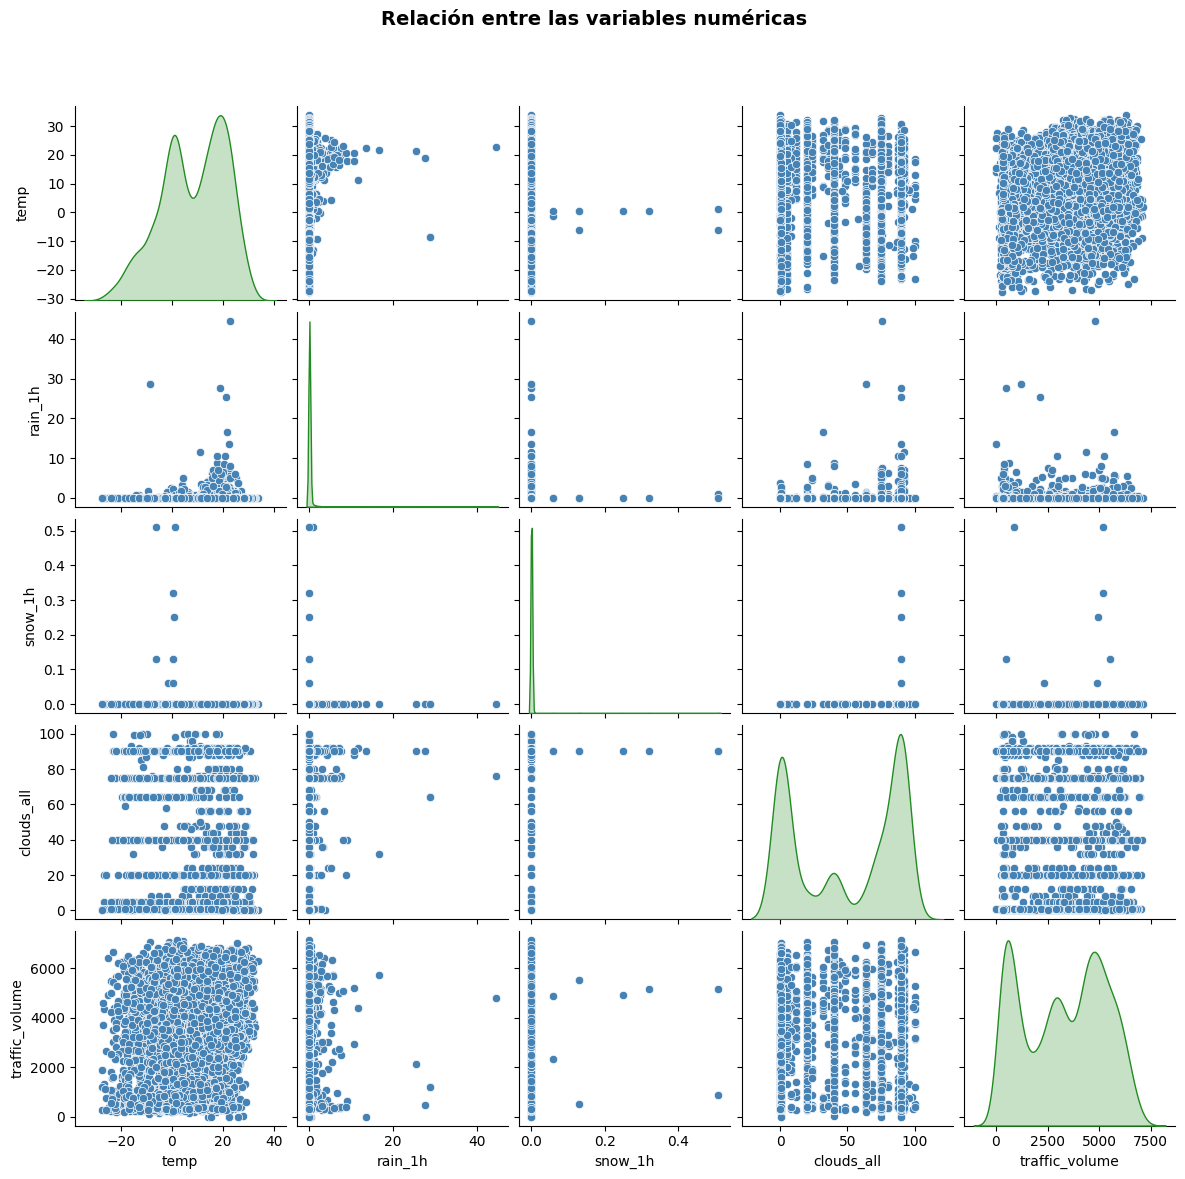

In [195]:
multiple_plot(1, d.sample(5000) , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

In [196]:
#Variable datetime

print(f"Fecha inicial: {d['date_time'].min()}")
print(f"Fecha final  : {d['date_time'].max()}")

Fecha inicial: 2012-10-02 09:00:00
Fecha final  : 2018-09-30 23:00:00


In [197]:
# Se agrega una variable year_month para efectos de la visualización
d['year_month'] = d['date_time'].dt.to_period('M')

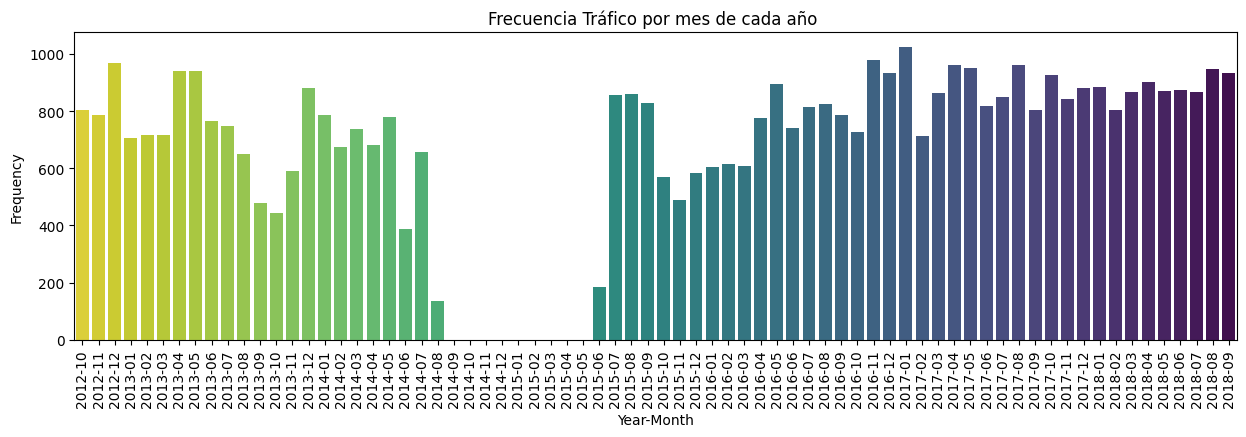

In [198]:
# Visualizar las frecuencias por mes de cada año

# Se cuenta la cantidad de registros por mes
freqCont = d['year_month'].value_counts().sort_index()

# Se crea un rango completo de meses desde el primer hasta el último mes en los datos
all_months = pd.period_range(start=freqCont.index.min(), end=freqCont.index.max(), freq='M')

# se reindexa la serie de frecuencias para incluir todos los meses, llenando los meses faltantes con cero
freqCont = freqCont.reindex(all_months, fill_value=0)

# Se convierte la serie a un DataFrame para usar con seaborn
freq_df = freqCont.reset_index()
freq_df.columns = ['Year-Month', 'Frequency']

# Se crea la gráfica de frecuencias por mes de cada año usando seaborn
plt.figure(figsize=(15, 4))
sns.barplot(x='Year-Month', y='Frequency', data=freq_df, palette='viridis_r')

plt.xlabel('Year-Month')
plt.ylabel('Frequency')
plt.title('Frecuencia Tráfico por mes de cada año ')
plt.xticks(rotation=90)

plt.show()

### Variable de salida

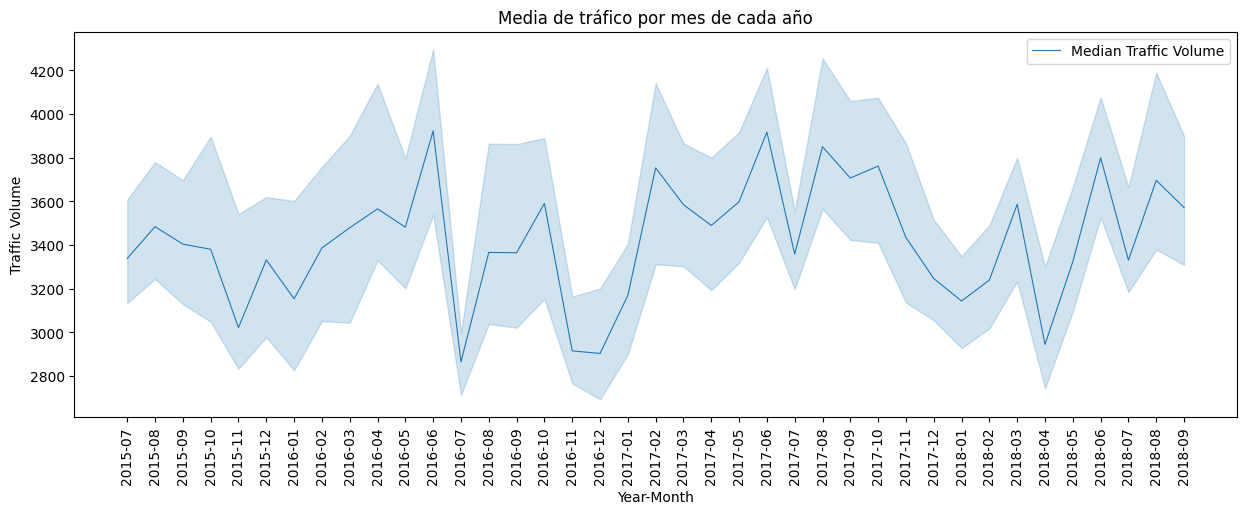

In [199]:
#Creación de la gráfica de mediana de tráfico por mes de cada año

start_date = '2015-07'
end_date = '2018-09'


#Filtrar los datos de acuerdo con start_date y end_date
df_filtered = d[(d['year_month'] >= start_date) & (d['year_month'] <= end_date)]


plt.figure(figsize=(15, 5))

sns.lineplot(
    x=df_filtered['year_month'].astype(str),
    y=df_filtered['traffic_volume'],
    estimator=np.median,
    #color="blue",
    linewidth=0.8,
    label='Median Traffic Volume'  # label para para la leyenda
)

plt.xlabel('Year-Month')
plt.ylabel('Traffic Volume')
plt.title('Media de tráfico por mes de cada año')
plt.xticks(rotation=90)

plt.legend()
plt.show()

## 5. Preparación de datos

### Creación de variables a partir de las existentes

In [200]:
df_features = df_filtered.copy()

In [201]:
# Creación de nuevas variables a partir de la variable 'date_time'

df_features["day_of_week"] = df_features["date_time"].dt.dayofweek #Lunes = 0, Martes = 1, etc.
df_features["weekend"]     = df_features["day_of_week"] > 4
df_features["weekend"]     = df_features["weekend"].astype(int)
df_features["hour"]        = df_features["date_time"].dt.hour
df_features["month"]       = df_features["date_time"].dt.month
df_features["day"]         = df_features["date_time"].dt.day
df_features["year"]        = df_features["date_time"].dt.year

In [202]:
# Convertir 'holiday' a binario

# Reemplazar los valores con la cadena 'None' en None
df_features["holiday"] = df_features["holiday"].fillna('None')

df_features["holiday"] = df_features["holiday"].apply(lambda x: 0 if x == 'None' else 1)

In [203]:
# Se encuentran las categorías que contienen el 99% de los datos para la variable: 'weather_main'


# Cuenta la frecuencia relativa acumulada de cada valor de la variable 'weather_main'
# aquellos de menos mayores de 99% seran marcados como False (el resto se marcará como True)
weather_list = d["weather_main"].value_counts(normalize=True).cumsum() <= 0.99


# Filtrar las categorías con pocas frecuencias (aquellas que quedaron en False)
low_freq_categories = weather_list[weather_list == False].index


# Crear el diccionario con las categorías de baja frecuencia
weather_dict = {category: "other" for category in low_freq_categories}


# Reemplazar los 'weather_main' con pocas ocurrencias ('Fog', 'Smoke', 'Squall') a una clase 'other'
df_features["weather_main"] = df_features["weather_main"].replace(weather_dict)


In [204]:
# Dummificación de 'weather_main'

df_features = pd.concat(
    [
        df_features,
        pd.get_dummies(df_features["weather_main"], drop_first=True, dtype=int),
    ],
    axis=1,
)

In [205]:
# Eliminación de características que no se van a utilizar

df_features = df_features.drop(
    columns=["weather_description", "weather_main", "rain_1h", "snow_1h", 'year_month']
)

In [206]:
# Convierte todos los nombres de las columnas del DataFrame df_features a minúsculas

df_features.columns = [col.lower() for col in df_features.columns]

In [207]:
#Eliminar las variables de la lista catCols

catCols = [col for col in catCols if col not in ["weather_description", "weather_main"]]

In [208]:
#Eliminar las variables de la lista numCols

numCols = [col for col in numCols if col not in ["rain_1h", "snow_1h"]]

### Duplicados

In [209]:
# Eliminación de duplicados
print(f"Filas antes de eliminar duplicados: {len(df_features)}")

df_features = df_features.drop_duplicates()
print(f"Filas después de eliminar duplicados: {len(df_features)}")

#Reiniciar el indice
d.reset_index(drop=True, inplace=True)

Filas antes de eliminar duplicados: 32047
Filas después de eliminar duplicados: 32030


### Outliers

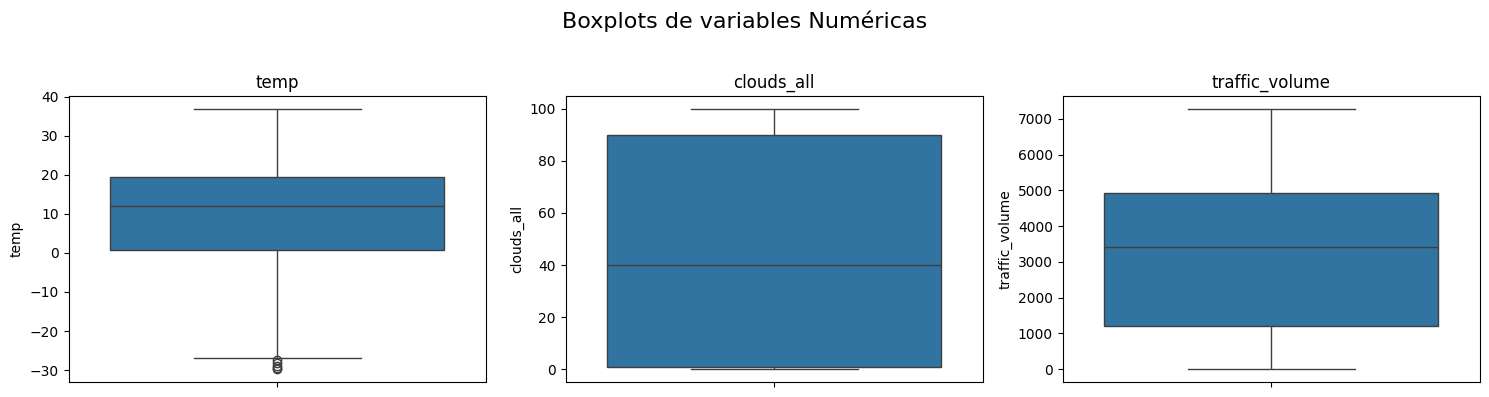

In [210]:
##Visualización de valores outliers para las variables categóricas

# Crear una figura con subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Crear un gráfico de boxplot para cada variable en su subplot correspondiente
for ax, col in zip(axes, numCols):
    sns.boxplot(y=df_features[col], ax=ax)
    ax.set_title(f'{col}')

# Agregar un título a la figura completa
fig.suptitle('Boxplots de variables Numéricas', fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [211]:
outliers_indices = identificar_outliers(df_features, numCols)
print("outliers:", outliers_indices)

outliers: [29248, 29249, 29250, 29251, 29252]


In [212]:
df_features.loc[outliers_indices].head()

,holiday,temp,clouds_all,date_time,traffic_volume,day_of_week,weekend,hour,month,day,year,clouds,drizzle,haze,mist,rain,snow,thunderstorm,other
29248,0,-27.5300,1,2016-12-18 04:00:00,277,6,1,4,12,18,2016,0,0,0,0,0,0,0,0
29249,0,-28.2600,1,2016-12-18 05:00:00,459,6,1,5,12,18,2016,0,0,0,0,0,0,0,0
29250,0,-28.9300,1,2016-12-18 06:00:00,800,6,1,6,12,18,2016,0,0,0,0,0,0,0,0
29251,0,-29.5300,1,2016-12-18 07:00:00,1037,6,1,7,12,18,2016,0,0,1,0,0,0,0,0
29252,0,-29.7600,1,2016-12-18 08:00:00,1462,6,1,8,12,18,2016,0,0,1,0,0,0,0,0


In [213]:
# Eliminar los valores atípicos del dataframe original
df_features = df_features.drop(outliers_indices)

## Análisis de variables

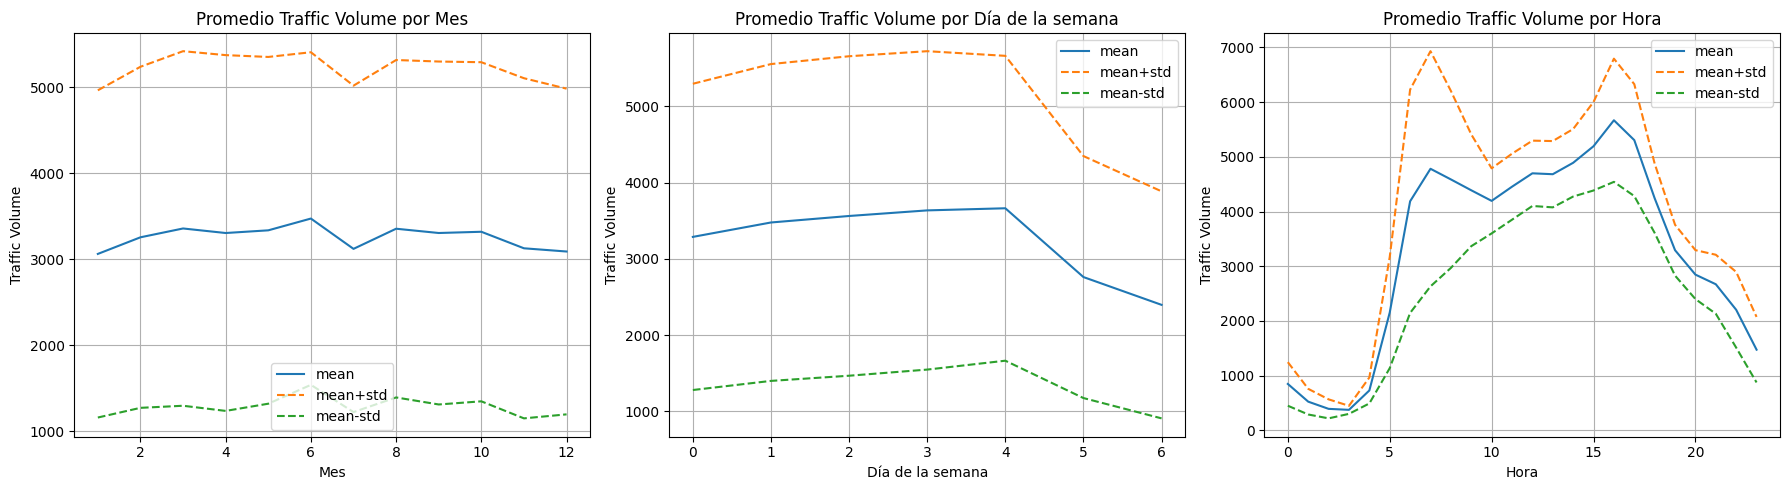

In [214]:
# Análisis de comportamiento del tráfico por mes, día y hora

# Lista de agrupaciones y títulos
groupings = [("month", "Mes"), ("day_of_week", "Día de la semana"), ("hour", "Hora")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Iterar sobre las agrupaciones y crear gráficos
for i, (group, label) in enumerate(groupings):
    stats = df_features.groupby(group, as_index=False)["traffic_volume"].agg(["mean", "std"]).reset_index()
    axes[i].plot(stats[group], stats["mean"], label="mean")
    axes[i].plot(stats[group], stats["mean"] + stats["std"], label="mean+std", linestyle='--')
    axes[i].plot(stats[group], stats["mean"] - stats["std"], label="mean-std", linestyle='--')
    axes[i].set_title(f"Promedio Traffic Volume por {label}")
    axes[i].set_xlabel(label)
    axes[i].set_ylabel("Traffic Volume")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [215]:
df_features.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32025 entries, 16157 to 48203
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   holiday         32025 non-null  int64         
 1   temp            32025 non-null  float64       
 2   clouds_all      32025 non-null  int64         
 3   date_time       32025 non-null  datetime64[ns]
 4   traffic_volume  32025 non-null  int64         
 5   day_of_week     32025 non-null  int32         
 6   weekend         32025 non-null  int64         
 7   hour            32025 non-null  int32         
 8   month           32025 non-null  int32         
 9   day             32025 non-null  int32         
 10  year            32025 non-null  int32         
 11  clouds          32025 non-null  int64         
 12  drizzle         32025 non-null  int64         
 13  haze            32025 non-null  int64         
 14  mist            32025 non-null  int64         
 15  rai

['clouds', 'drizzle', 'haze', 'mist', 'rain', 'snow', 'thunderstorm', 'other', 'weekend']


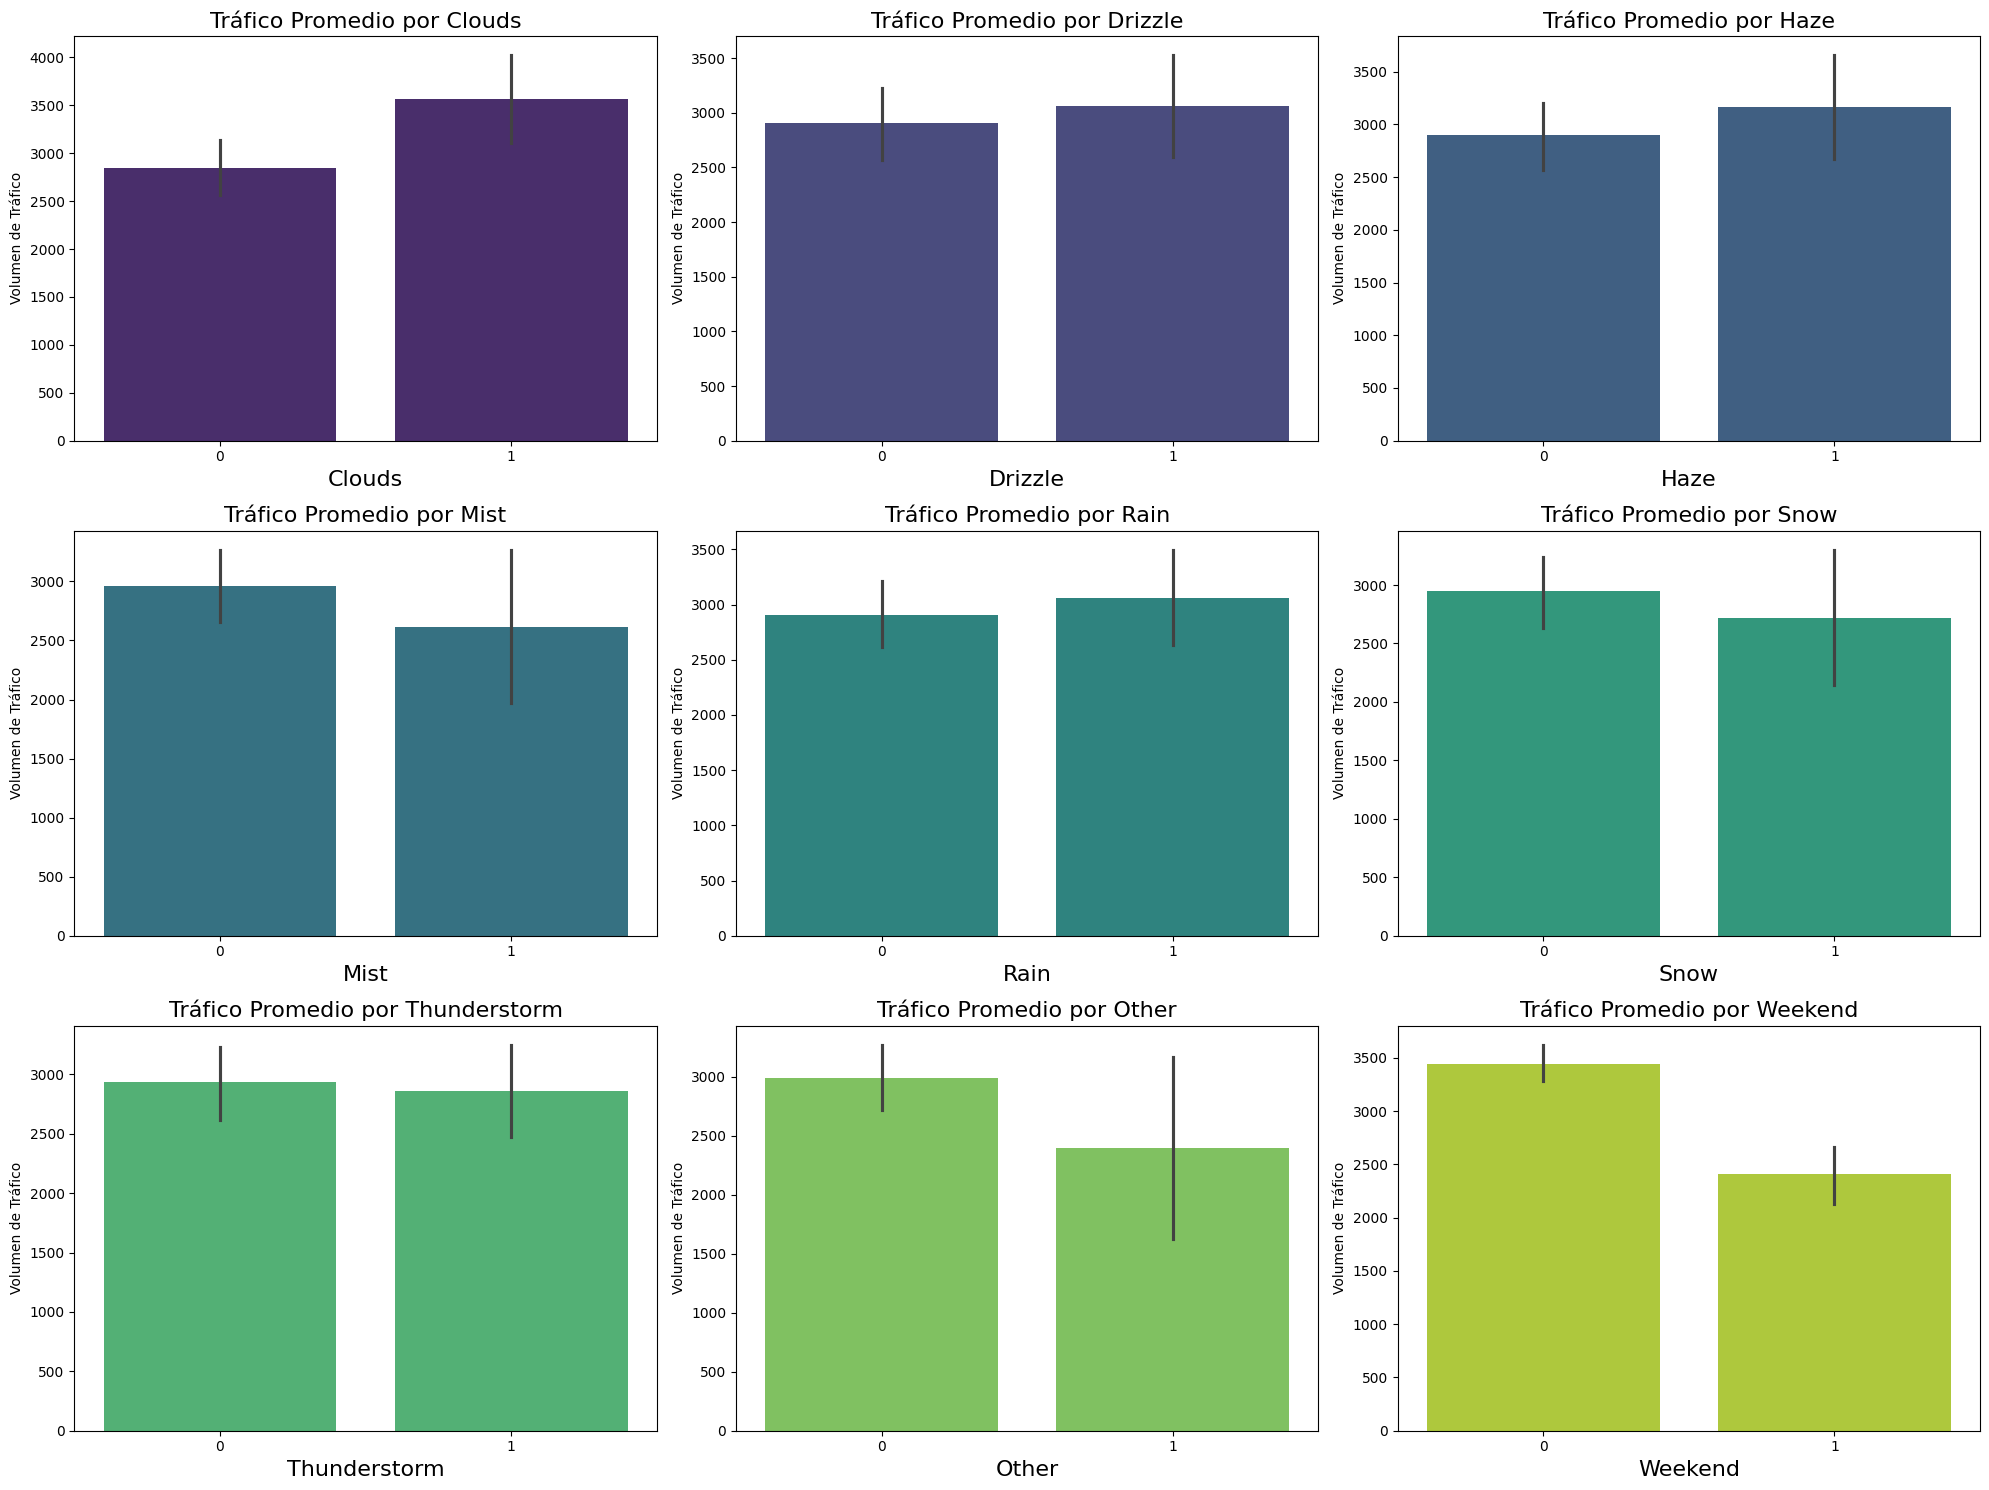

In [216]:
# Lista de variables

variables = ['clouds', 'drizzle', 'haze', 'mist', 'rain', 'snow', 'thunderstorm', 'other', 'weekend']
print(variables)

# Generar una lista de colores
colors = sns.color_palette("viridis", len(variables))

# Calcular el volumen promedio de tráfico para cada variable
traffic_means = df_features.groupby(variables).traffic_volume.mean().reset_index()

# Crear una figura con subplots
fig, axes = plt.subplots(3, 3, figsize=(20, 15))

# Iterar sobre las variables y crear gráficos de barras
for i, var in enumerate(variables):
    row = i // 3
    col = i % 3
    sns.barplot(data=traffic_means, x=var, y="traffic_volume", ax=axes[row, col], color=colors[i])

    axes[row, col].set_title(f"Tráfico Promedio por {var.capitalize()}",fontsize=16)
    axes[row, col].set_xlabel(var.capitalize(), fontsize=16)
    axes[row, col].set_ylabel("Volumen de Tráfico")

plt.tight_layout()
plt.show()

## Train Test Split y Escalamiento de Variables

In [217]:
# se extrae una muestra  (solo para graficar)
df_features_sample = df_features.sample(1000, random_state=123)

# Se definen las fechas de corte para los filtros de la gráfica
cutoff_year_upper = 2017
cutoff_month_upper = 7

# Crear una máscara para los datos de entrenamiento y prueba y aplicar los filtros

# Datos de entrenamiento hasta 2017-07
train_mask = ((df_features["year"] < cutoff_year_upper) |
              ((df_features["year"] == cutoff_year_upper) & (df_features["month"] <= cutoff_month_upper)))

# Datos de test mayores 2017-07
test_mask = (df_features["year"] > cutoff_year_upper) | \
            ((df_features["year"] == cutoff_year_upper) & (df_features["month"] > cutoff_month_upper))

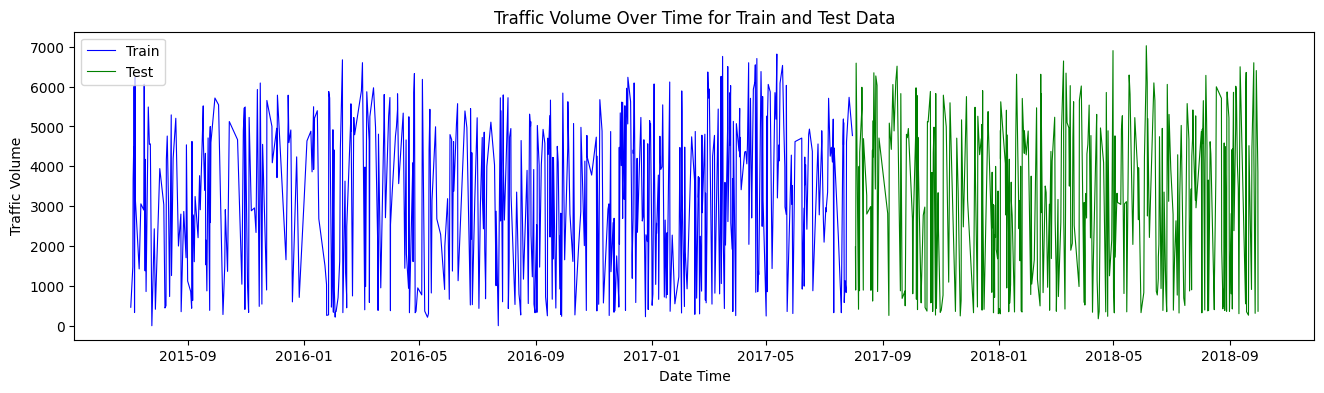

In [218]:
# Crear la gráfica de líneas
plt.figure(figsize=(16, 4))

# Graficar datos de entrenamiento
sns.lineplot(
    x=df_features_sample[train_mask]['date_time'],
    y=df_features_sample[train_mask]['traffic_volume'],
    color="blue",
    label="Train",
    linewidth=0.8
)

# Graficar datos de prueba
sns.lineplot(
    x=df_features_sample[test_mask]['date_time'],
    y=df_features_sample[test_mask]['traffic_volume'],
    color="green",
    label="Test",
    linewidth=0.8
)

plt.xlabel('Date Time')
plt.ylabel('Traffic Volume')
plt.title('Traffic Volume Over Time for Train and Test Data')
plt.legend()
plt.show()

In [219]:
df_features = df_features.drop(columns=["date_time"])
numCols.remove("traffic_volume")

In [220]:
#Datos de prueba (10%) con datos de test mayores 2017-07
dfPrueba = df_features[test_mask].sample(frac=0.1, random_state=123)

In [221]:
# Separación de variables de entrada y variable de salida
X = df_features.drop(columns=["traffic_volume"])
y = df_features["traffic_volume"]

# Crear máscaras para excluir los registros del dfPrueba
exclude_mask = ~df_features.index.isin(dfPrueba.index)

# Filtrar X y y para excluir los registros de dfPrueba
X_filtered = X[exclude_mask]
y_filtered = y[exclude_mask]

# Crear conjuntos de entrenamiento y prueba
X_train = X_filtered[train_mask]
X_test = X_filtered[test_mask]
y_train = y_filtered[train_mask]
y_test = y_filtered[test_mask]

In [222]:
#Escalar Variables númericas (todas)

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Escalado de datos
scaler = MinMaxScaler()

# Escalado de datos
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convertir a dataframes
X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [223]:
X_train.head(2)

,holiday,temp,clouds_all,day_of_week,weekend,hour,month,day,year,clouds,drizzle,haze,mist,rain,snow,thunderstorm,other
0,0.0000,0.7015,0.0100,0.3333,0.0000,0.0000,0.5455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.0000,0.7048,0.0100,0.3333,0.0000,0.0435,0.5455,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 6. Creación de modelos

MASE:

El MASE (Mean Absolute Scaled Error) es una métrica para evaluar modelos de series de tiempo que mide el error del modelo comparado con un modelo naive (básico).

Un modelo naive se refiere a qué tan bien predice el modelo en relación con “repetir el último valor” o el “promedio de los ultimos días”


- MASE < 1: el modelo lo hace mejor que el naive. Por ejemplo, 0,7 significa que se equivoca un 30 % menos.
- MASE = 1: es igual de bueno que el naive, así que el modelo no aporta nada.
- MASE > 1: es peor que el naive.


Es útil porque es interpretable, comparable entre problemas y robusto a la escala de los datos.


| MASE        | Evaluación        |
|------------|------------------|
| < 0.5      | 🔥 Excelente      |
| 0.5 – 0.8  | ✅ Bueno          |
| 0.8 – 1.0  | ⚠️ Marginal       |
| > 1.0      | ❌ Malo           |

### Regresión Lineal

In [224]:
# Se crea el modelo de Regresión lineal
lr = LinearRegression()

# Se entrena el modelo
lr.fit(X_train, y_train)

LinearRegression()

In [225]:
# Evaluación del modelo

lr_model_train_metrics = eval_model(lr, X_train, y_train)
lr_model_train_metrics["name"] = type(lr).__name__

lr_model_test_metrics = eval_model(lr, X_test, y_test)
lr_model_test_metrics["name"] = type(lr).__name__

print(lr_model_train_metrics)
print(lr_model_test_metrics)

{'mae': 1542.98923, 'rmse': 1765.9388, 'r2': 0.19396, 'mase': 2.91721, 'name': 'LinearRegression'}
{'mae': 1558.99249, 'rmse': 1779.82326, 'r2': 0.1983, 'mase': 2.92442, 'name': 'LinearRegression'}


### Decision Tree Regressor

In [226]:
# Se crea el modelo de Árbol de decisión
dtr = DecisionTreeRegressor(random_state=1234, max_depth=5)

# Se entrena el modelo
dtr.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5, random_state=1234)

In [227]:
# Evaluación del modelo

dtr_model_train_metrics = eval_model(dtr, X_train, y_train)
dtr_model_train_metrics["name"] = type(dtr).__name__

dtr_model_test_metrics = eval_model(dtr, X_test, y_test)
dtr_model_test_metrics["name"] = type(dtr).__name__

print(dtr_model_train_metrics)
print(dtr_model_test_metrics)

{'mae': 385.69391, 'rmse': 595.0625, 'r2': 0.90848, 'mase': 0.7292, 'name': 'DecisionTreeRegressor'}
{'mae': 401.87113, 'rmse': 620.0436, 'r2': 0.9027, 'mase': 0.75385, 'name': 'DecisionTreeRegressor'}


### Random Forest Regressor

In [228]:
# Se crea el modelo de random Forest
rfr = RandomForestRegressor(random_state=1234, bootstrap=True, max_depth=5)

# Se entrena el modelo
rfr.fit(X_train, y_train)

RandomForestRegressor(max_depth=5, random_state=1234)

In [229]:
# Evaluación del modelo

rfr_model_train_metrics = eval_model(rfr, X_train, y_train)
rfr_model_train_metrics["name"] = type(rfr).__name__

rfr_model_test_metrics = eval_model(rfr, X_test, y_test)
rfr_model_test_metrics["name"] = type(rfr).__name__

print(rfr_model_train_metrics)
print(rfr_model_test_metrics)

{'mae': 380.88364, 'rmse': 591.41947, 'r2': 0.90959, 'mase': 0.72011, 'name': 'RandomForestRegressor'}
{'mae': 399.32111, 'rmse': 618.67739, 'r2': 0.90313, 'mase': 0.74906, 'name': 'RandomForestRegressor'}


## 7. Evaluación de modelos

In [230]:
# Creación de dataframes para comparar resultados entre los modelos

# dataframe de métricas de train (ordenadas por mase)
df_compare_train = pd.DataFrame(
    [
        lr_model_train_metrics,
        dtr_model_train_metrics,
        rfr_model_train_metrics,
    ]
).sort_values(by="mase", ascending=True)

# dataframe de métricas de test (ordenadas por mase)
df_compare_test = pd.DataFrame(
    [
        lr_model_test_metrics,
        dtr_model_test_metrics,
        rfr_model_test_metrics,
    ]
).sort_values(by="mase", ascending=True)

In [231]:
# Se crea un dataframe a partir de df_compare_train y df_compare_test
df_combined_inner = pd.merge(df_compare_train, df_compare_test, on='name', suffixes=('_train', '_test'))

# Definir el orden deseado de las columnas
colOrd = ['name','mae_train', 'mae_test', 'rmse_train', 'rmse_test', 'r2_train', 'r2_test', 'mase_train', 'mase_test']

# Reordenar las columnas
df_combined_inner = df_combined_inner[colOrd]

df_combined_inner[colOrd].sort_values(by="mae_test", ascending=True)

,name,mae_train,mae_test,rmse_train,rmse_test,r2_train,r2_test,mase_train,mase_test
0,RandomForestRegressor,380.8836,399.3211,591.4195,618.6774,0.9096,0.9031,0.7201,0.7491
1,DecisionTreeRegressor,385.6939,401.8711,595.0625,620.0436,0.9085,0.9027,0.7292,0.7539
2,LinearRegression,1542.9892,1558.9925,1765.9388,1779.8233,0.1940,0.1983,2.9172,2.9244


### Ajuste de parámetros al mejor modelo

In [232]:
# Definir rangos de búsqueda para cada parámetro
rfr_search_ranges = {
    "n_estimators": np.arange(20, 100, 20),
    "max_depth": np.arange(2, 16, 2),
    "max_features": np.arange(2, 16, 2),
}

# Definir parámetros base del modelo
rfr_base_params = {"random_state": 4321, "bootstrap": True, "max_depth": 5}

Ajustando para n_estimators=20
Ajustando para n_estimators=40
Ajustando para n_estimators=60
Ajustando para n_estimators=80


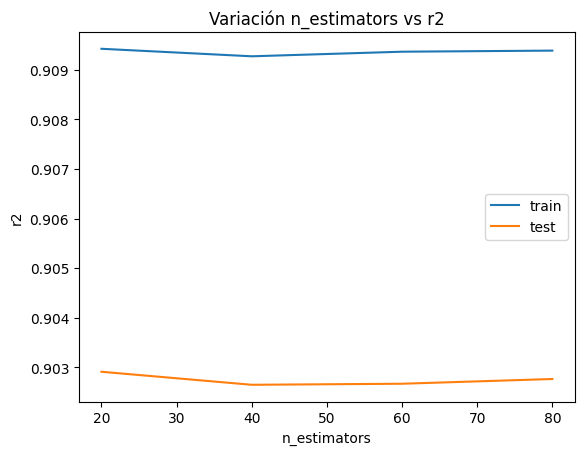

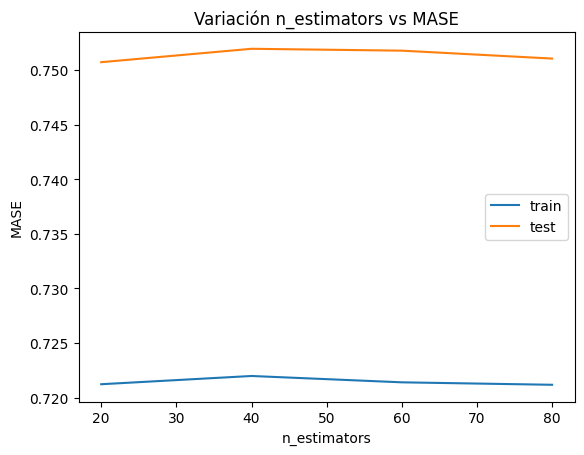

--------------------------------------------------

Ajustando para max_depth=2
Ajustando para max_depth=4
Ajustando para max_depth=6
Ajustando para max_depth=8
Ajustando para max_depth=10
Ajustando para max_depth=12
Ajustando para max_depth=14


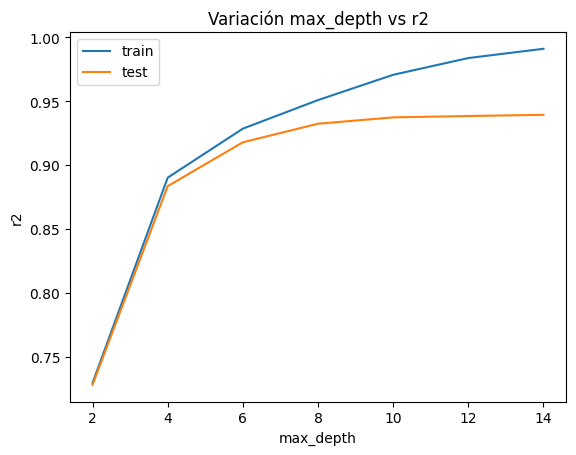

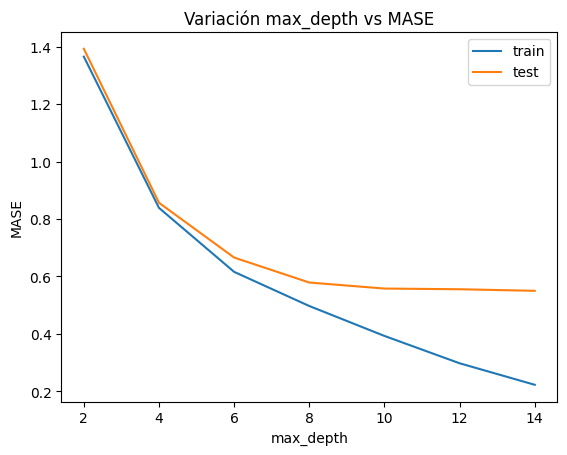

--------------------------------------------------

Ajustando para max_features=2
Ajustando para max_features=4
Ajustando para max_features=6
Ajustando para max_features=8
Ajustando para max_features=10
Ajustando para max_features=12
Ajustando para max_features=14


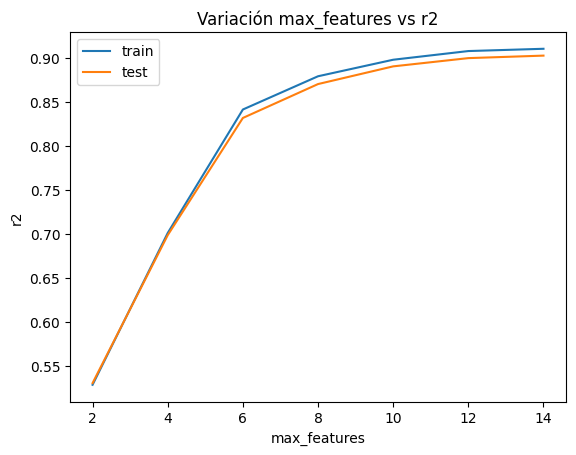

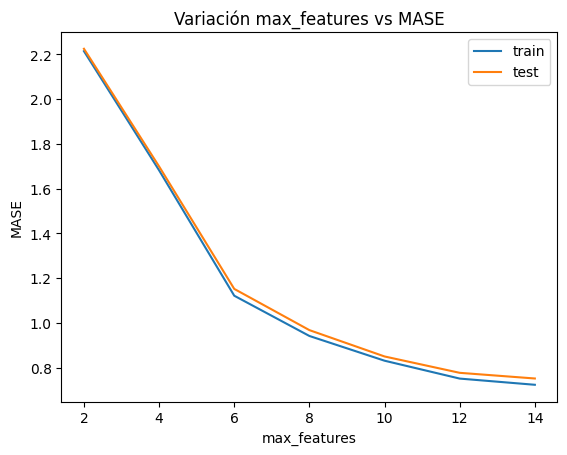

--------------------------------------------------



In [233]:
# Búsqueda de parámetros
for param, search_range in rfr_search_ranges.items():
    r2_scores_rfr, mase_scores_rfr = search_param(
        RandomForestRegressor(),
        X_train,
        y_train,
        X_test,
        y_test,
        rfr_base_params,
        param,
        search_range,
    )
    plot_param_perf(
        search_range, r2_scores_rfr, f"Variación {param} vs r2", param, "r2"
    )
    plot_param_perf(
        search_range, mase_scores_rfr, f"Variación {param} vs MASE", param, "MASE"
    )
    print("-" * 50 + "\n")

In [234]:
# Definición de búsqueda de parámetros
hyper_params = {
    "n_estimators": [20, 30, 40],
    "max_depth": [5, 6, 7, 8, 9],
    "max_features": [10, 11, 12, 13, 14],
}
# Inicialización del objeto del modelo
rfr = RandomForestRegressor(**rfr_base_params)


# TimeSeriesSplit respeta el orden temporal de los datos, permite evitar
# el "look-ahead bias" (usar información futura para predecir el pasado).
tscv = TimeSeriesSplit(
                        n_splits=5, # Número de divisiones (splits) a realizar en los datos
                        gap=24)     # Los registros estan dados en horas, entonces se omiten 24 observaciones (1 dia)
                                    # entre el conjunto de entrenamiento y el conjunto de prueba. Permite asegurarse
                                    # que los datos utilizados para entrenar un modelo de series temporales no incluyan
                                    # información futura que podría influir en los resultados del modelo.
                                    # Esto es crucial para mantener la integridad y la validez de los pronósticos

# Grid Search
grid_search_rfr = GridSearchCV(
    estimator=rfr,
    param_grid=hyper_params,
    cv=tscv,
    scoring="r2",
    verbose=1,
    n_jobs=-1,
)
grid_search_rfr.fit(X_train, y_train)

Fitting 5 folds for each of 75 candidates, totalling 375 fits


GridSearchCV(cv=TimeSeriesSplit(gap=24, max_train_size=None, n_splits=5, test_size=None),
             estimator=RandomForestRegressor(max_depth=5, random_state=4321),
             n_jobs=-1,
             param_grid={'max_depth': [5, 6, 7, 8, 9],
                         'max_features': [10, 11, 12, 13, 14],
                         'n_estimators': [20, 30, 40]},
             scoring='r2', verbose=1)

In [235]:
resultados = pd.DataFrame(grid_search_rfr.cv_results_)
resultados.filter(regex="(param.*|mean_t|std_t|mean_f)").drop(
    columns="params"
).sort_values(["mean_test_score", "mean_fit_time"], ascending=False).head(5)

,mean_fit_time,param_max_depth,param_max_features,param_n_estimators,mean_test_score,std_test_score
68,0.9862,9,12,40,0.9222,0.0240
67,1.0969,9,12,30,0.9217,0.0248
59,1.6109,8,14,40,0.9212,0.0221
74,1.0814,9,14,40,0.9211,0.0235
64,0.6833,9,11,30,0.9210,0.0254


In [236]:
# Resultados promedio de r2 score en cada pliegue del mejor estimador
pd.DataFrame(grid_search_rfr.cv_results_).filter(regex="split.*_test_score").loc[
    grid_search_rfr.best_index_
]

,68
split0_test_score,0.9053
split1_test_score,0.8846
split2_test_score,0.9308
split3_test_score,0.9397
split4_test_score,0.9505


In [237]:
# Escoger el mejor Random Forest
best_rfr = grid_search_rfr.best_estimator_

best_rfr.fit(X_train, y_train)

RandomForestRegressor(max_depth=9, max_features=12, n_estimators=40,
                      random_state=4321)

In [238]:
# Evaluación en datos de entrenamiento
y_train_pred = best_rfr.predict(X_train)
print(f"Train R2: {r2_score(y_train, y_train_pred):.4f}")
print(
    f"Train MASE: {mean_absolute_scaled_error(y_train, y_train_pred, y_train=y_train):.4f} \n"
)


# Evaluación en datos de prueba
    #No estacional: y_train=y_test
    #Estacional: y_train=y_train[:-period]

y_test_pred = best_rfr.predict(X_test)
print(f"Test R2: {r2_score(y_test, y_test_pred):.4f}")
print(
    f"Test MASE: {mean_absolute_scaled_error(y_test, y_test_pred, y_train=y_test):.4f}"
)

Train R2: 0.9613
Train MASE: 0.4550 

Test R2: 0.9345
Test MASE: 0.5728


### Selección entre los Mejores  Modelos

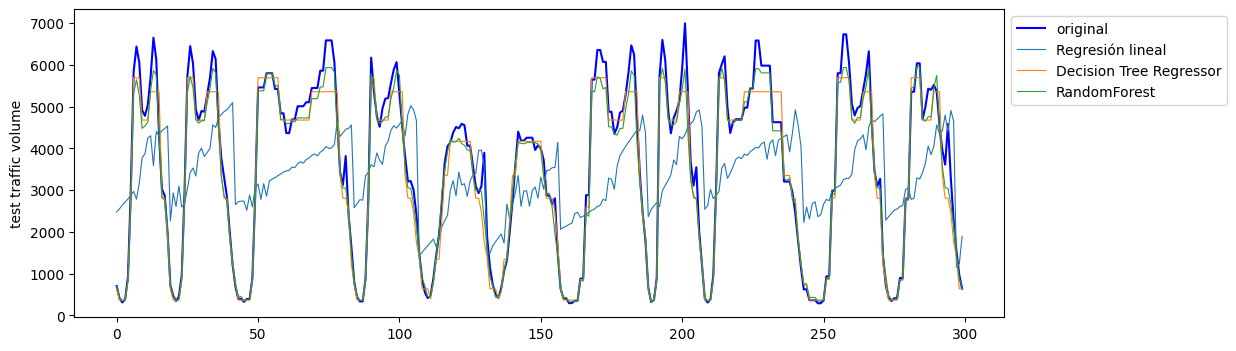

In [239]:
# Rangos de registros a visualizar
start =0
end = 300

# Resultados en los datos de prueba para los mejores modelos
predictions = {
    "Regresión lineal": lr.predict(X_test),
    "Decision Tree Regressor": dtr.predict(X_test),
    "RandomForest": best_rfr.predict(X_test)
}

# Crear DataFrame para la comparación de los modelos
ts_df = pd.DataFrame({"test traffic volume": y_test.values})
ts_df = ts_df.assign(**{f"predicted traffic volume {name}": pred for name, pred in predictions.items()})


# Función para graficar un rango de tiempo específico
#def plot_time_range(ts_df, start, end):
plt.figure(figsize=(12, 4))  # Ajusta el tamaño de la figura

# Graficar una ventana de tiempo de los datos de prueba junto con los resultados de los mejores modelos
sns.lineplot(data=ts_df["test traffic volume"][start:end], color="blue", label="original")

for name in predictions.keys():
    sns.lineplot(data=ts_df[f"predicted traffic volume {name}"][start:end], label=name, linewidth=0.8)

plt.legend(bbox_to_anchor=(1, 1))
plt.show()

#### Dataset de Prueba

In [240]:
# Separación de variables de entrada y variable de salida
Xp = dfPrueba.drop(columns=["traffic_volume"])
yp = dfPrueba["traffic_volume"]

In [241]:
#Escalar Variables númericas

pd.set_option('display.float_format', lambda x: '%.4f' % x)


# Escalado de datos
Xp_scaled = scaler.transform(Xp)

## Convertir a dataframes
Xp_scaled = pd.DataFrame(Xp_scaled, columns=Xp.columns)

In [242]:
Xp_scaled.head(2)

,holiday,temp,clouds_all,day_of_week,weekend,hour,month,day,year,clouds,drizzle,haze,mist,rain,snow,thunderstorm,other
0,0.0000,0.7491,0.0100,0.3333,0.0000,0.0870,0.4545,0.1667,1.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.0000,0.6817,0.0100,0.6667,0.0000,0.2609,0.6364,0.5667,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000


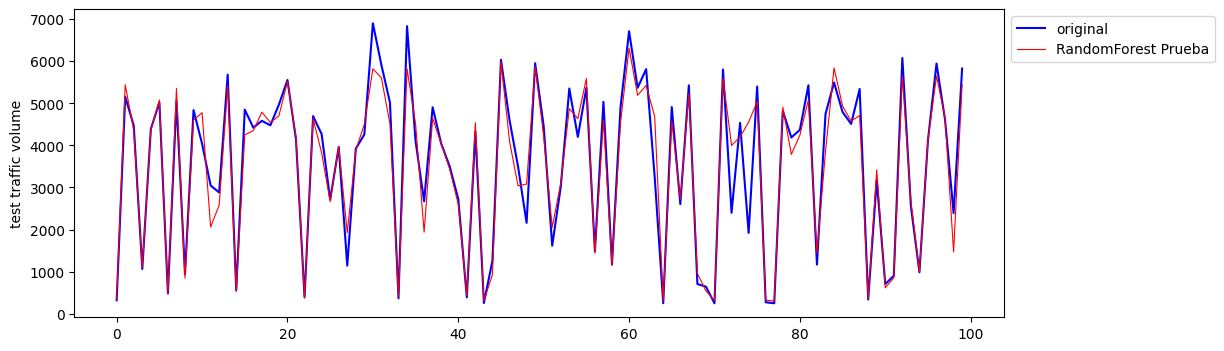

In [243]:
# Rangos de registros a visualizar
start =0
end = 100

# Resultados en los datos de prueba para el mejor modelo
predictions = {
    "RandomForest Prueba": best_rfr.predict(Xp_scaled)
}

# Crear DataFrame para la comparación de los modelos
ts_df = pd.DataFrame({"test traffic volume": yp.values})
ts_df = ts_df.assign(**{f"predicted traffic volume {name}": pred for name, pred in predictions.items()})


# Función para graficar un rango de tiempo específico
#def plot_time_range(ts_df, start, end):
plt.figure(figsize=(12, 4))  # Ajusta el tamaño de la figura

# Graficar una ventana de tiempo de los datos de prueba junto con los resultados de los mejores modelos
sns.lineplot(data=ts_df["test traffic volume"][start:end], color="blue", label="original")

for name in predictions.keys():
    sns.lineplot(data=ts_df[f"predicted traffic volume {name}"][start:end], label=name, color="red", linewidth=0.8)

plt.legend(bbox_to_anchor=(1, 1))
plt.show()

In [244]:
# Evaluación en datos de entrenamiento
y_train_pred = best_rfr.predict(X_train)
print(f"Train R2: {r2_score(y_train, y_train_pred):.4f}")
print(
    f"Train MASE: {mean_absolute_scaled_error(y_train, y_train_pred, y_train=y_train):.4f} \n"
)

# Evaluación en datos de prueba
y_pred_rfr = best_rfr.predict(Xp_scaled)
print(f"Prueba R2: {r2_score(yp, y_pred_rfr):.4f}")
print(
    f"Prueba MASE: {mean_absolute_scaled_error(yp, y_pred_rfr, y_train=yp):.4f}"
)

Train R2: 0.9613
Train MASE: 0.4550 

Prueba R2: 0.9333
Prueba MASE: 0.1332


In [245]:
dfPrueba

,holiday,temp,clouds_all,traffic_volume,day_of_week,weekend,hour,month,day,year,clouds,drizzle,haze,mist,rain,snow,thunderstorm,other
44717,0,18.9400,1,318,2,0,2,6,6,2018,0,0,0,0,0,0,0,0
36383,0,14.8500,1,5156,4,0,6,8,18,2017,0,0,0,1,0,0,0,0
41266,0,-14.7400,75,4470,0,0,11,2,5,2018,1,0,0,0,0,0,0,0
42506,0,-3.2100,1,1062,1,0,23,3,20,2018,0,0,0,0,0,0,0,0
42290,0,3.8500,1,4388,0,0,18,3,12,2018,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39356,0,3.6900,1,5862,3,0,6,11,30,2017,0,0,0,0,0,0,0,0
47160,0,16.4500,90,4624,1,0,10,8,28,2018,0,0,0,0,1,0,0,0
37534,0,11.2800,40,6062,3,0,6,9,28,2017,0,0,0,0,1,0,0,0
40388,0,-25.5300,5,2487,5,1,8,1,6,2018,0,0,1,0,0,0,0,0


In [246]:
# Convertir la lista de predicciones a un DataFrame
df_predicciones = pd.DataFrame(best_rfr.predict(Xp_scaled), columns=['predicted_traffic_volume'], index=dfPrueba.index)

# Unir dfPrueba con df_predicciones
df_resultado = pd.concat([dfPrueba, df_predicciones], axis=1)
df_resultado.head(2)

,holiday,temp,clouds_all,traffic_volume,day_of_week,weekend,hour,month,day,year,clouds,drizzle,haze,mist,rain,snow,thunderstorm,other,predicted_traffic_volume
44717,0,18.9400,1,318,2,0,2,6,6,2018,0,0,0,0,0,0,0,0,336.5546
36383,0,14.8500,1,5156,4,0,6,8,18,2017,0,0,0,1,0,0,0,0,5441.3185


In [247]:
# Agregar una columna de error con la diferencia entre el valor real y el pronosticado
df_resultado['error'] = df_resultado['traffic_volume'] - df_resultado['predicted_traffic_volume']

df_resultado[['traffic_volume', 'predicted_traffic_volume', 'error']].sort_values(by='error', ascending=False)[450:550]

,traffic_volume,predicted_traffic_volume,error
40131,1310,1133.6679,176.3321
42583,3049,2872.8722,176.1278
37199,2174,1998.6440,175.3560
40250,2995,2820.9537,174.0463
43512,3139,2967.5702,171.4298
...,...,...,...
38925,4690,4591.8891,98.1109
43680,3026,2929.0794,96.9206
35976,3091,2994.5743,96.4257
46852,941,844.8220,96.1780


In [248]:
# Calcular el error absoluto
df_resultado['absolute_error'] = df_resultado['error'].abs()

# Calcular el error promedio del valor absoluto
error_promedio_absoluto = df_resultado['absolute_error'].mean()

# Calcular la mediana del valor absoluto del error
mediana_error_absoluto = df_resultado['absolute_error'].median()

print(f"Error promedio absoluto   : {error_promedio_absoluto}")
print(f"Mediana del error absoluto: {mediana_error_absoluto}")

Error promedio absoluto   : 311.094346755347
Mediana del error absoluto: 187.84697245900816


In [249]:
df_resultado[['traffic_volume', 'predicted_traffic_volume','absolute_error']] \
    .sort_values(by='absolute_error', ascending=True)

,traffic_volume,predicted_traffic_volume,absolute_error
37258,4349,4348.9592,0.0408
45461,419,418.9360,0.0640
41341,882,882.0833,0.0833
47786,858,858.4922,0.4922
47785,858,857.2602,0.7398
...,...,...,...
45559,1920,4554.9616,2634.9616
47349,1995,4716.7886,2721.7886
40263,811,3910.9940,3099.9940
43262,1478,4634.6485,3156.6485


#### Referencias


- Random Forest
    - https://cienciadedatos.net/documentos/py44-multi-series-forecasting-skforecast-espa%C3%B1ol.html
    - https://cienciadedatos.net/documentos/py27-forecasting-series-temporales-python-scikitlearn
    - https://www.youtube.com/watch?v=_0J-a1IQjjQ
    